## Analyzing a player's dismissals patterns, strengths and weaknesses

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np

In [22]:
# Load the comprehensive player data CSV file generated from JSON files
player_dismissal_file = 'data/all_players_batting_stats.csv'
data = pd.read_csv(player_dismissal_file)

# Display the first few rows of the DataFrame
print(data.head())

  Player Name       Team     Bowler Type       Span  Dis  bwd  caught  st  \
0   DA Warner  Australia   left-arm-pace  2002-2024   24    2      18   0   
1   DA Warner  Australia  right-arm-spin  2002-2024   30    7      13   1   
2   DA Warner  Australia  right-arm-pace  2002-2024   89   15      63   0   
3   DA Warner  Australia   left-arm-spin  2002-2024   12    1       8   0   
4   DA Warner  Australia         unknown  2002-2024    0    0       0   0   

   lbw  hw  ro  oth  dot_balls    Ave    BF  Runs  
0    3   0   1    0        573  36.00   981   864  
1    4   0   2    3        690  39.43  1369  1183  
2    4   0   4    3       2128  45.12  3985  4016  
3    1   0   1    1        383  63.25   835   759  
4    0   0   0    0         43   0.00   104   110  


In [23]:
# Display the summary of the DataFrame
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7678 entries, 0 to 7677
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Player Name  7678 non-null   object 
 1   Team         7678 non-null   object 
 2   Bowler Type  7678 non-null   object 
 3   Span         7678 non-null   object 
 4   Dis          7678 non-null   int64  
 5   bwd          7678 non-null   int64  
 6   caught       7678 non-null   int64  
 7   st           7678 non-null   int64  
 8   lbw          7678 non-null   int64  
 9   hw           7678 non-null   int64  
 10  ro           7678 non-null   int64  
 11  oth          7678 non-null   int64  
 12  dot_balls    7678 non-null   int64  
 13  Ave          7678 non-null   float64
 14  BF           7678 non-null   int64  
 15  Runs         7678 non-null   int64  
dtypes: float64(1), int64(11), object(4)
memory usage: 959.9+ KB
None


## Extracting Player's Statistics

In [24]:
# Define the player name dynamically
player_name = "Babar Azam" #"V Kohli"  # Dynamic input for any player

# Check if the player name exists in the DataFrame
if player_name in data['Player Name'].values:
    # Filter the DataFrame to get all the stats for the selected player
    player_data = data[data['Player Name'] == player_name]

    # Display the data for the player
    print(f"Data for {player_name}:")
    print(player_data)
else:
    # Output an error message if the player is not found
    print(f"Error: Player '{player_name}' not found in the DataFrame.")
    # Raise an exception to stop further execution
    raise ValueError(f"Player '{player_name}' not found in the DataFrame.")


Data for Babar Azam:
   Player Name      Team     Bowler Type       Span  Dis  bwd  caught  st  \
64  Babar Azam  Pakistan   left-arm-pace  2002-2024    9    0       7   0   
65  Babar Azam  Pakistan  right-arm-pace  2002-2024   59   12      38   0   
66  Babar Azam  Pakistan  right-arm-spin  2002-2024   26    2      12   4   
67  Babar Azam  Pakistan   left-arm-spin  2002-2024    8    3       3   1   
68  Babar Azam  Pakistan         unknown  2002-2024    1    0       1   0   

    lbw  hw  ro  oth  dot_balls     Ave    BF  Runs  
64    2   0   0    0        294   54.00   546   486  
65    5   0   4    0       1659   46.98  3171  2772  
66    5   0   1    2        844   64.73  1953  1683  
67    0   0   0    1        361   83.00   797   664  
68    0   0   0    0         61  124.00   138   124  


# Analysis of Dismissal Types for the player

In [25]:
#Drop rows where 'Bowler Type' is 'mixture/unknown'
player_data_filtered = player_data[player_data['Bowler Type'] != 'unknown']

In [26]:
# List of dismissal types
dismissal_types = ['bwd', 'caught', 'st', 'lbw', 'hw', 'ro']

# Aggregate dismissal counts
dismissal_counts = player_data[dismissal_types].sum()

# Display the aggregated dismissal counts
print(dismissal_counts)

bwd       17
caught    61
st         5
lbw       12
hw         0
ro         5
dtype: int64


A pie chart visualization will display the different ways the player has been dismissed, showing the proportion of each dismissal type. This chart provides a clear and concise view of the frequency of each dismissal type

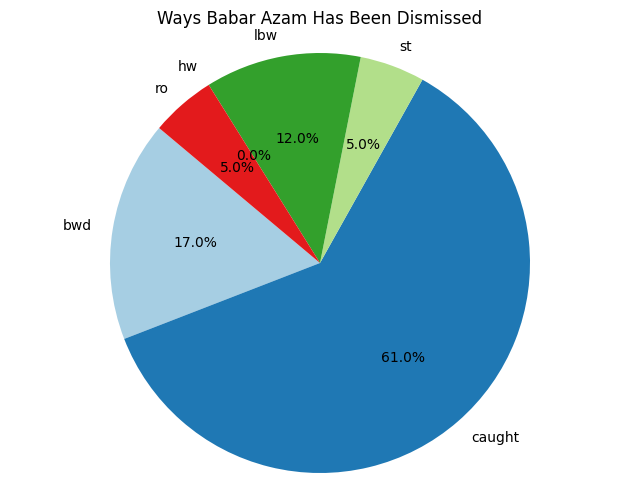

In [27]:
# pie chart
plt.figure(figsize=(8, 6))
plt.pie(dismissal_counts, labels=dismissal_counts.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(dismissal_counts))), startangle=140)
plt.title(f'Ways {player_name} Has Been Dismissed')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

Dismissals of the player against diffrent bowler types

In [28]:
# Aggregate dismissal counts by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')[dismissal_types].sum().reset_index()

# Display the aggregated dismissal counts
print(dismissals_by_bowler_type)

      Bowler Type  bwd  caught  st  lbw  hw  ro
0   left-arm-pace    0       7   0    2   0   0
1   left-arm-spin    3       3   1    0   0   0
2  right-arm-pace   12      38   0    5   0   4
3  right-arm-spin    2      12   4    5   0   1


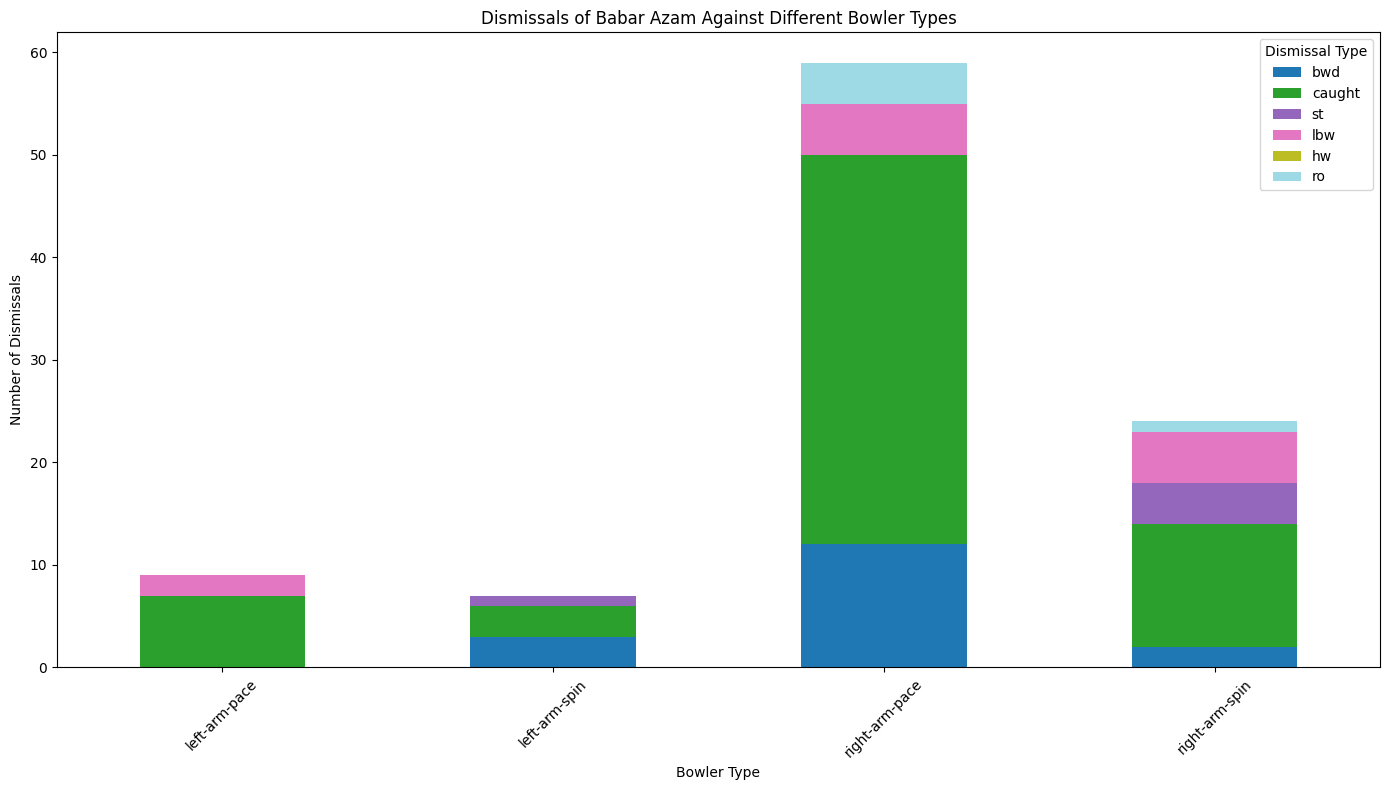

In [29]:
# Plot a stacked bar plot
dismissals_by_bowler_type.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')
plt.title(f'Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Number of Dismissals')
plt.legend(title='Dismissal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [30]:
# dismissals_by_bowler_type.head
dismissals_by_bowler_type.columns

Index(['Bowler Type', 'bwd', 'caught', 'st', 'lbw', 'hw', 'ro'], dtype='object')

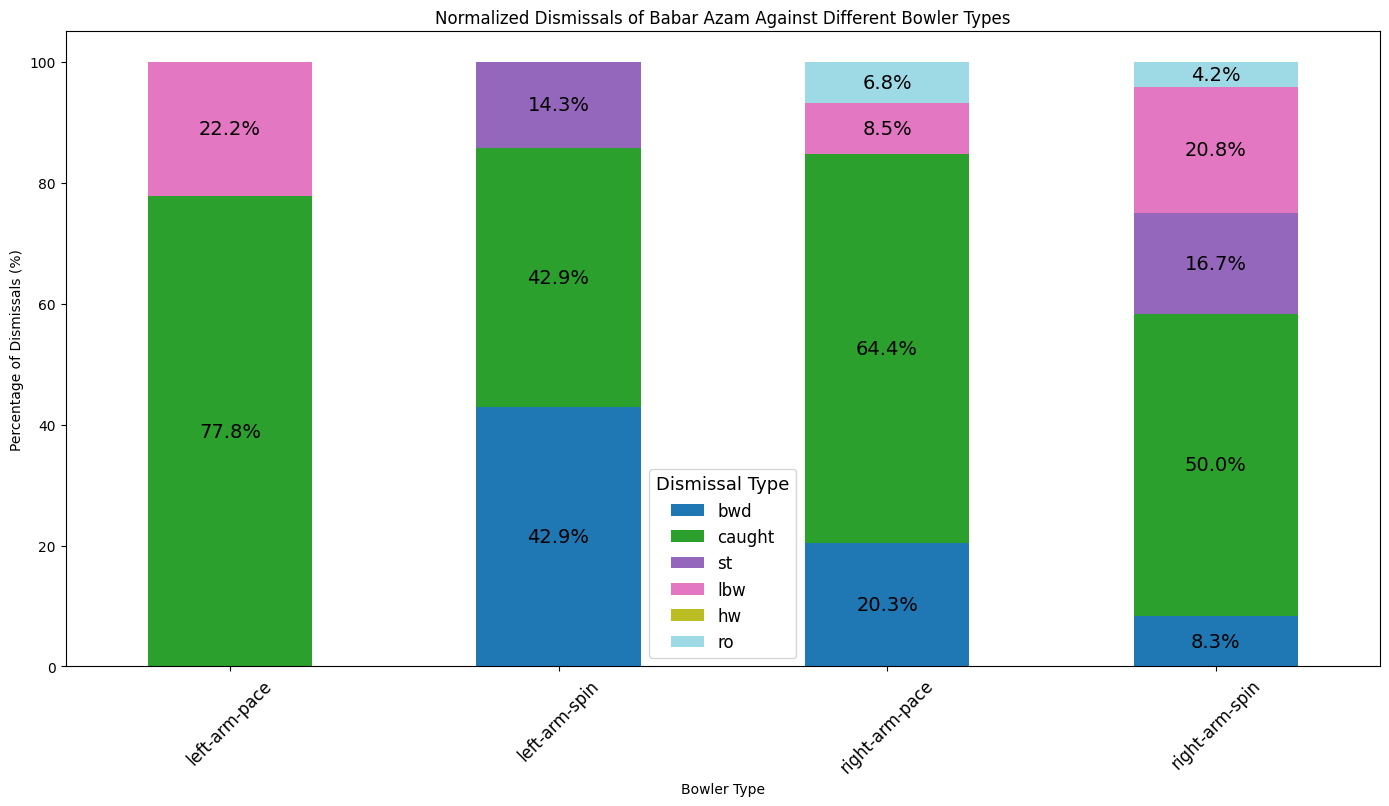

In [31]:
# Calculate total dismissals for each bowler type
dismissals_by_bowler_type['Total Dismissals'] = dismissals_by_bowler_type[dismissal_types].sum(axis=1)

# Normalize each dismissal type by the total dismissals for that bowler type
for dismissal_type in dismissal_types:
    dismissals_by_bowler_type[dismissal_type] = (dismissals_by_bowler_type[dismissal_type] / dismissals_by_bowler_type['Total Dismissals']) * 100

# Drop the total dismissals column as it's no longer needed
dismissals_by_bowler_type.drop(columns='Total Dismissals', inplace=True)

# Plot the normalized stacked bar plot
ax = dismissals_by_bowler_type.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

# Add labels and title
plt.title(f'Normalized Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Percentage of Dismissals (%)')
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels within the bars
for i in range(dismissals_by_bowler_type.shape[0]):
    bottom = 0
    for j, col in enumerate(dismissal_types):
        value = dismissals_by_bowler_type.iloc[i][col]
        if value > 0:
            ax.text(i, bottom + value / 2, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=14)
        bottom += value

ax.legend(title='Dismissal Type', title_fontsize=13, fontsize=12)
ax.tick_params(axis='x', labelsize=12)

# Show the plot
plt.show()


Normalizing the dismissals by each bowler against the player with the balls faced

In [32]:
# Aggregate total dismissals and balls faced by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Dis'].sum().reset_index()
balls_faced_by_bowler_type = player_data_filtered.groupby('Bowler Type')['BF'].sum().reset_index()

# Merge the two DataFrames
dismissals_balls = pd.merge(dismissals_by_bowler_type, balls_faced_by_bowler_type, on='Bowler Type')

# Calculate dismissal rate per ball faced
dismissals_balls['Dismissal Rate'] = dismissals_balls['Dis'] / dismissals_balls['BF']

# Display the normalized dismissal rates
print(dismissals_balls)

      Bowler Type  Dis    BF  Dismissal Rate
0   left-arm-pace    9   546        0.016484
1   left-arm-spin    8   797        0.010038
2  right-arm-pace   59  3171        0.018606
3  right-arm-spin   26  1953        0.013313


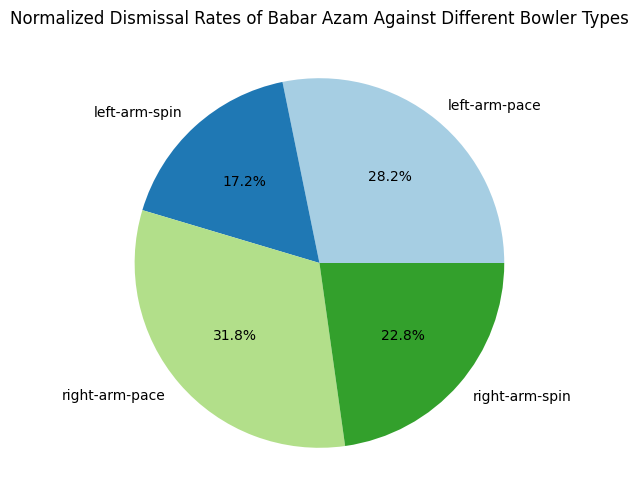

In [33]:
# Prepare data for pie plot
pie_data = dismissals_balls.set_index('Bowler Type')['Dismissal Rate']

# Plot a pie chart
plt.figure(figsize=(8, 6))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(pie_data))))
plt.title(f'Normalized Dismissal Rates of {player_name} Against Different Bowler Types')
plt.show()

# Analysis of Runs Scored for the player

Extracting the Runs data of selected player

In [34]:
# Aggregate total runs scored against each bowler type
runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Runs'].sum().reset_index()

# Display the aggregated data
print(runs_by_bowler_type)

      Bowler Type  Runs
0   left-arm-pace   486
1   left-arm-spin   664
2  right-arm-pace  2772
3  right-arm-spin  1683


Bar plot of Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

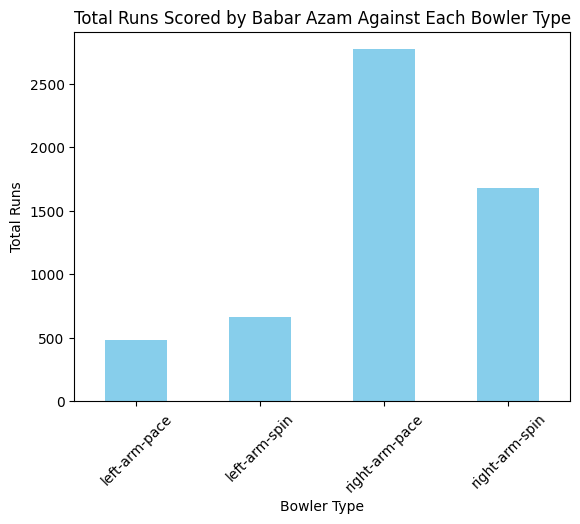

In [35]:
plt.figure(figsize=(12, 6))
runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Runs', color='skyblue', legend=False)
plt.title(f'Total Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

Plot both runs scored and balls faced by the player for each bowler type

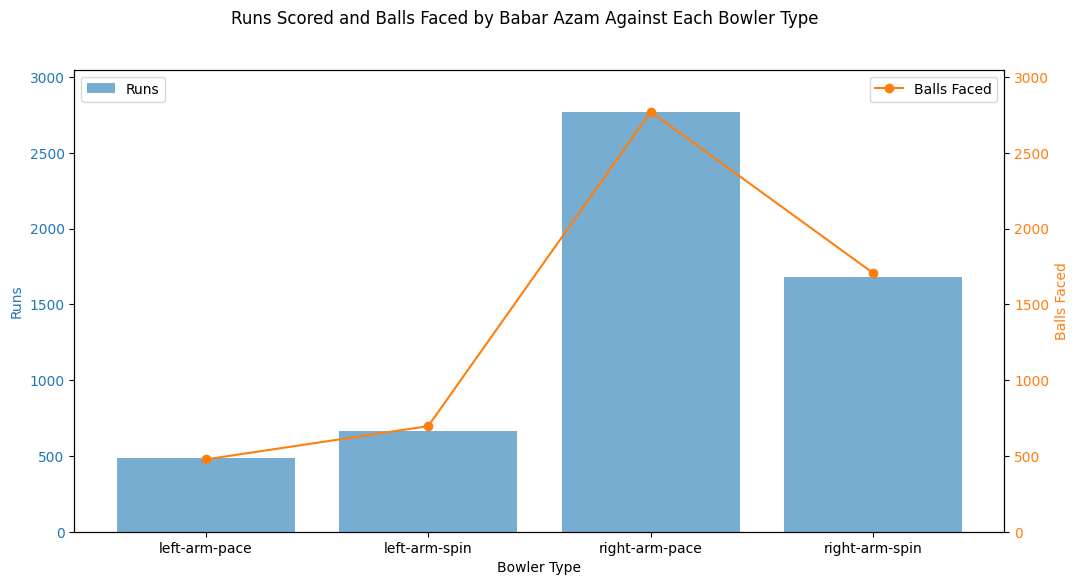

In [36]:
import matplotlib.pyplot as plt

# Aggregate total runs and balls faced against each bowler type
runs_balls_by_bowler_type = player_data_filtered.groupby('Bowler Type').agg({'Runs': 'sum', 'BF': 'sum'}).reset_index()

# Determine the common limit based on the maximum value of runs and balls faced
max_runs = runs_balls_by_bowler_type['Runs'].max()
max_balls_faced = runs_balls_by_bowler_type['BF'].max()

# Calculate scaling factor to normalize the secondary axis to the primary axis range
scaling_factor = max_runs / max_balls_faced

# Create a dual-axis plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Runs on the primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs'], color=color, alpha=0.6, label='Runs')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, max_runs * 1.1)  # Extend limit a bit for better visibility

# Create a secondary y-axis for Balls Faced
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Balls Faced', color=color)
# Normalize the Balls Faced data to align with the Runs data range
ax2.plot(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['BF'] * scaling_factor, color=color, marker='o', label='Balls Faced')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max_runs * 1.1)  # Use the same range as the primary y-axis

# Add titles and legends
fig.suptitle(f'Runs Scored and Balls Faced by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()


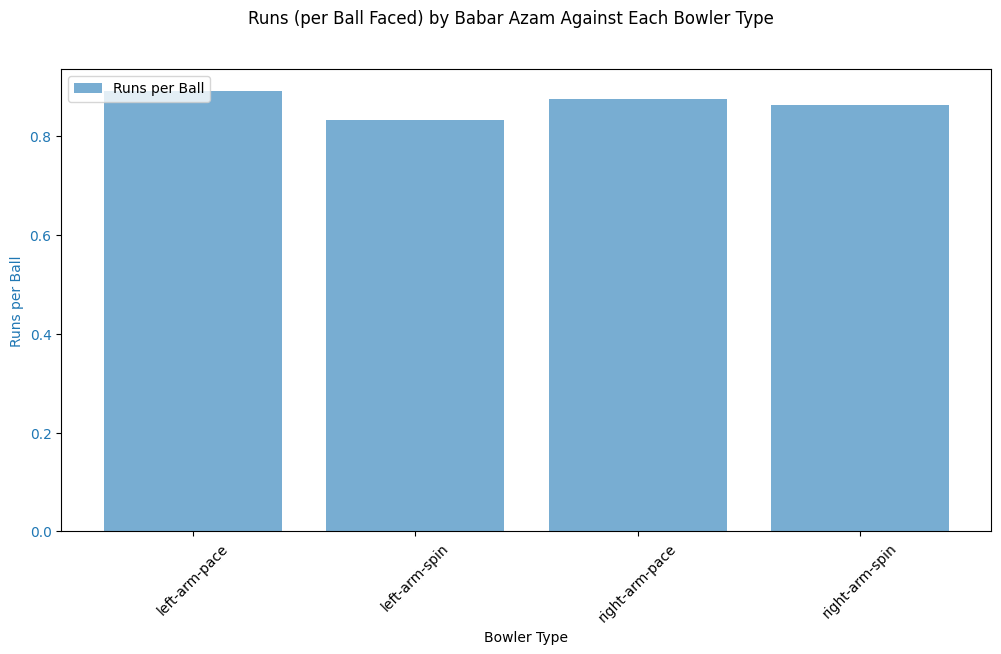

In [37]:
# Normalize runs against balls faced by calculating runs per ball
runs_balls_by_bowler_type['Runs per Ball'] = runs_balls_by_bowler_type['Runs'] / runs_balls_by_bowler_type['BF']

# Plot the normalized data
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot normalized runs per ball
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs per Ball', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs per Ball'], color=color, alpha=0.6, label='Runs per Ball')
ax1.tick_params(axis='y', labelcolor=color)

# Add titles and legend
fig.suptitle(f'Runs (per Ball Faced) by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()

Plot of average runs scored by the player against each bowler type

In [38]:
# Average runs scored against each bowler type
avg_runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Ave'].sum().reset_index()

# Display the aggregated data
print(avg_runs_by_bowler_type)

      Bowler Type    Ave
0   left-arm-pace  54.00
1   left-arm-spin  83.00
2  right-arm-pace  46.98
3  right-arm-spin  64.73


Bar plot of Average Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

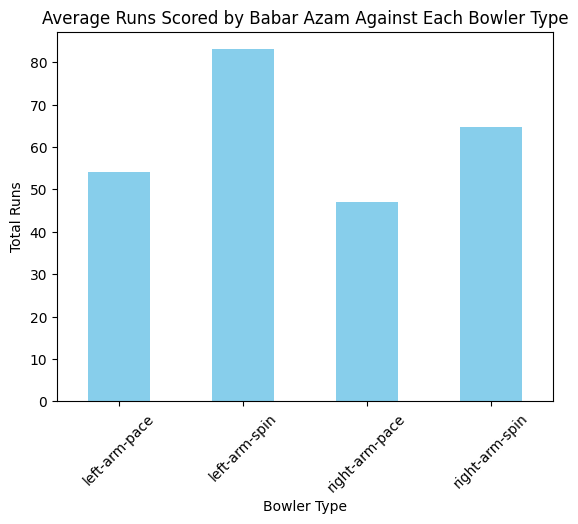

In [39]:
plt.figure(figsize=(12, 6))
avg_runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Ave', color='skyblue', legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

Pie plot of avg runs for % visualization

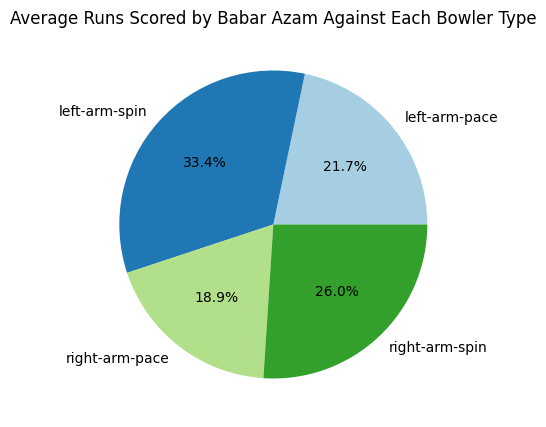

In [40]:
plt.figure(figsize=(5, 5))
avg_runs_by_bowler_type.set_index('Bowler Type')['Ave'].plot(kind='pie', autopct='%1.1f%%', colors=plt.cm.Paired(range(len(avg_runs_by_bowler_type))), legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.ylabel('')
plt.show()